# Natural-image denoising and noise mismatch
Compare BayesShrink wavelets, the noisy baseline and frozen SwinIR on the same 400
COCO test images. The model was trained externally at sigma 25; sigma 15 and 50 test
noise shift. [Full protocol](../docs/12_generative_restoration.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

from io import BytesIO
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, display
def preview(path):
    # Compressed display preview; full-resolution scientific figures remain in assets.
    with PILImage.open(path) as picture:
        picture.thumbnail((760,760))
        buffer = BytesIO()
        picture.convert('RGB').save(buffer,format='JPEG',quality=90)
    display(NotebookImage(data=buffer.getvalue()))

In [2]:
m = evidence('natural_denoising')
pd.DataFrame([{'model':r['model'],'sigma':r['sigma'],
              **{k:r[k]['mean'] for k in ['psnr','ssim','lpips']}} for r in m['rows']])

,model,sigma,psnr,ssim,lpips
0,noisy,15,24.887280,0.563015,0.223129
1,wavelet,15,29.889789,0.804630,0.134237
2,swinir_noise25,15,32.595051,0.889430,0.115948
3,noisy,25,20.627805,0.392531,0.415874
4,wavelet,25,27.182096,0.720213,0.219951
5,swinir_noise25,25,32.208640,0.900773,0.063092
6,noisy,50,15.125587,0.205928,0.812253
7,wavelet,50,23.982962,0.598740,0.366367
8,swinir_noise25,50,17.586362,0.274294,0.644725


## Shared noise and paired error
Whole-image Gaussian noise is generated once and scaled by sigma. It is shared
across methods and not clipped before inference. Predictions are clipped for metrics.
The wavelet method receives the known sigma, whereas SwinIR stays frozen at sigma25.

In [3]:
scores = np.load(root/'assets/source_data/natural_denoising_per_image_scores.npz')
rows = []
rng = np.random.default_rng(8)
for sigma in [15,25,50]:
    delta = scores[f'swinir_noise25_sigma{sigma}_psnr']-scores[f'wavelet_sigma{sigma}_psnr']
    sampled = delta[rng.integers(len(delta),size=(2000,len(delta)))].mean(1)
    rows.append({'sigma':sigma,'paired PSNR difference':delta.mean(),
                 'CI lower':np.quantile(sampled,.025),'CI upper':np.quantile(sampled,.975)})
pd.DataFrame(rows)

,sigma,paired PSNR difference,CI lower,CI upper
0,15,2.705262,2.571381,2.851756
1,25,5.026544,4.902150,5.157708
2,50,-6.396599,-6.571400,-6.230293


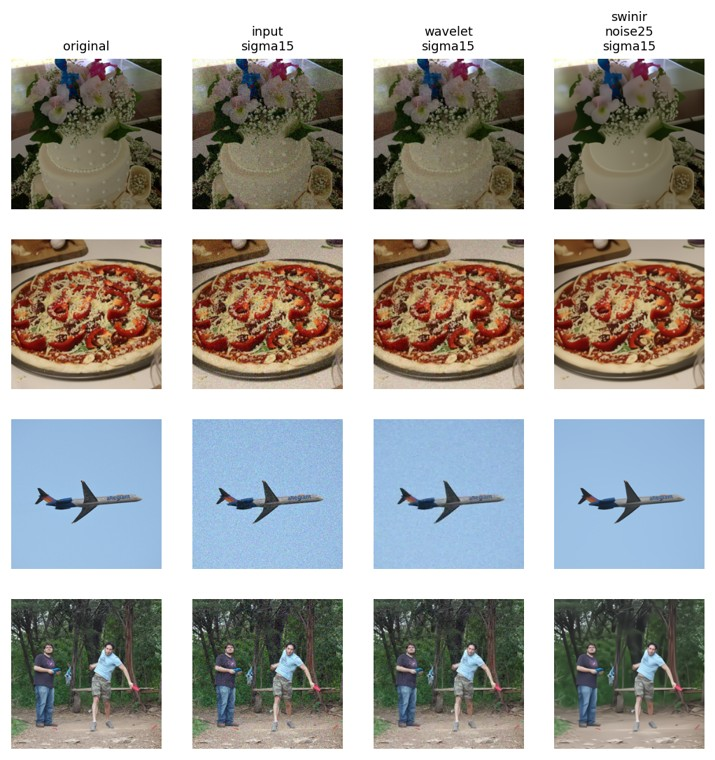

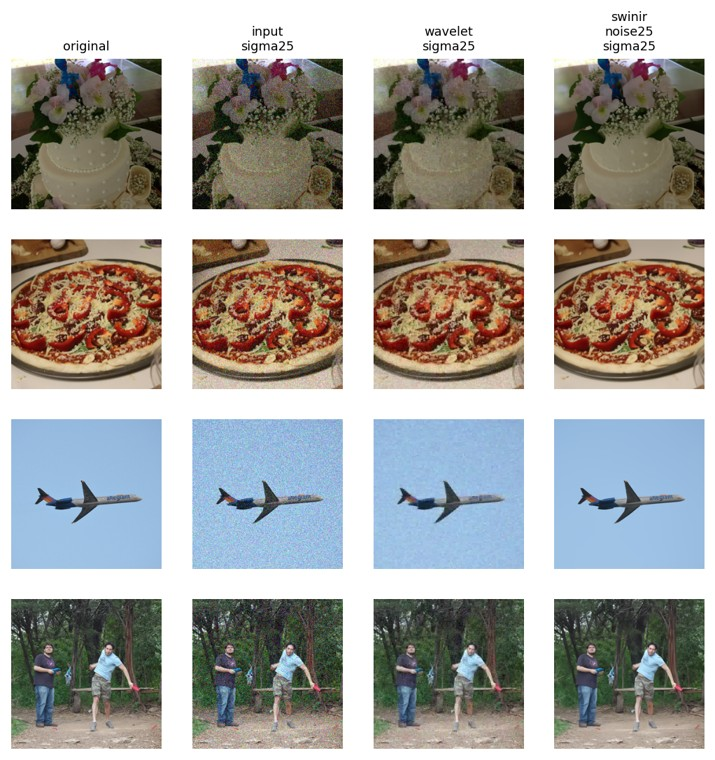

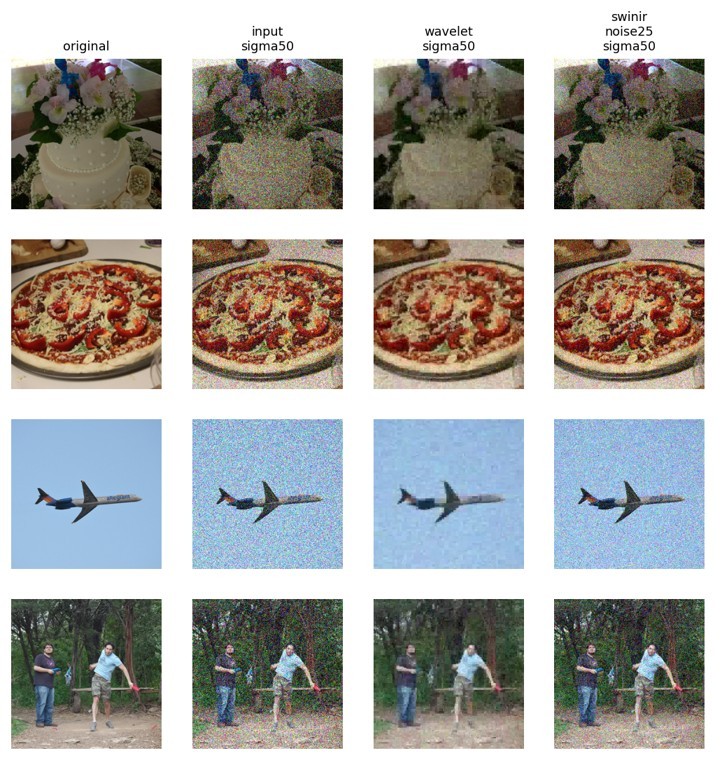

In [4]:
from IPython.display import Image,display
for sigma in [15,25,50]:
    preview(root/f'assets/natural_denoising_sigma{sigma}_gallery.png')

## Worked answer
Why retain the sigma50 result where the wavelet baseline wins? It exposes the
learned model's sensitivity to its observation model. Removing it would hide a
deployment failure. A future remedy could condition on sigma or train across noise
levels, but neither remedy is claimed as an executed result in this study.